# 02 — Machine Learning

This notebook trains and evaluates models on spectral features computed from
`.Q00` conductivity fluctuation measurements.

It uses the combined dataset produced by `src/signal_processing.py` and
reproduces the pipeline implemented in `src/train_models.py`.

Stable Bi, Cr, and Fe films are used for supervised material recognition.
XXX reference films and irradiated films are excluded from training.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = BASE_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

DATASET_PATH = BASE_DIR / "data" / "processed" / "conductivity_features.csv"
FIGURES_DIR = BASE_DIR / "results" / "figures"
METRICS_DIR = BASE_DIR / "results" / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_LABEL = "XXX"
MATERIAL_ORDER = ["BI", "CR", "FE"]
RANDOM_STATE = 42

MATERIAL_NAMES = {
    "BI": "Bismuth (Bi)",
    "CR": "Chromium (Cr)",
    "FE": "Iron (Fe)",
    "XXX": "Reference film",
}

MATERIAL_COLORS = {
    "BI": "#4C72B0",
    "CR": "#DD8452",
    "FE": "#55A868",
    "XXX": "#000000",
}

print("Dataset:", DATASET_PATH)
print("Figures:", FIGURES_DIR)
print("Metrics:", METRICS_DIR)

Dataset: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\conductivity_features.csv
Figures: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\results\figures
Metrics: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\results\metrics


## Load the combined feature dataset

The dataset must first be created by running:

```bash
python src/signal_processing.py
```

In [2]:
df = pd.read_csv(DATASET_PATH)

print(f"Rows: {len(df)}")
print(f"Files: {df['file'].nunique()}")
print(f"Columns: {list(df.columns)}")

df.head()

Rows: 1145619
Files: 15
Columns: ['gamma', 'energy', 'jd1', 'jd2', 'file', 'material', 'material_name', 'year', 'measurement_period', 'irradiated', 'sampling_rate_hz', 'log_energy', 'used_for_training']


,gamma,energy,jd1,jd2,file,material,material_name,year,measurement_period,irradiated,sampling_rate_hz,log_energy,used_for_training
0,0.398660,1.571536e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.803676,True
1,-0.175839,3.100287e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.508598,True
2,-0.094906,1.338760e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.873297,True
3,-0.136083,1.224634e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.911994,True
4,-0.094538,1.233776e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.908764,True


## Dataset overview

Only stable, non-irradiated Bi, Cr, and Fe films are used for supervised
learning. The `used_for_training` column is produced by
`src/signal_processing.py`.

In [3]:
df["material"].value_counts()

material
BI     336875
CR     336875
FE     336875
XXX    134994
Name: count, dtype: int64

In [4]:
df.groupby(["material", "irradiated", "used_for_training"]).size()

material  irradiated  used_for_training
BI        False       True                 126738
          True        False                210137
CR        False       True                 126738
          True        False                210137
FE        False       True                 126738
          True        False                210137
XXX       False       False                134994
dtype: int64

## Prepare training data

The training set contains only stable films marked as `used_for_training`.
Reference films (`XXX`) and irradiated films are excluded.

In [5]:
def prepare_training_data(df: pd.DataFrame):
    df_train = df[
        (df["used_for_training"] == True)
        & (df["material"] != REFERENCE_LABEL)
        & (df["irradiated"] == False)
    ].copy()

    X = df_train[["gamma", "log_energy"]].copy()
    y = df_train["material"].copy()

    return X, y, df_train


X, y, df_train = prepare_training_data(df)

print(f"Training samples: {len(X)}")
print("Class distribution:")
print(y.value_counts())

X.head()

Training samples: 380214
Class distribution:
material
BI    126738
CR    126738
FE    126738
Name: count, dtype: int64


,gamma,log_energy
0,0.398660,-8.803676
1,-0.175839,-8.508598
2,-0.094906,-8.873297
3,-0.136083,-8.911994
4,-0.094538,-8.908764


## Train-test split

The split is stratified by material class and uses a fixed random seed.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")

print("\nTrain class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Train size: 285160
Test size: 95054

Train class distribution:
material
BI    95054
CR    95053
FE    95053
Name: count, dtype: int64

Test class distribution:
material
FE    31685
CR    31685
BI    31684
Name: count, dtype: int64


## Feature standardization

The scaler is fitted only on the training set and then applied to the test set.

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
).describe()

,gamma,log_energy
count,2.851600e+05,2.851600e+05
mean,-1.385404e-17,2.242560e-16
std,1.000002e+00,1.000002e+00
min,-6.859822e+00,-1.722915e+01
25%,-4.157723e-01,-5.358395e-01
50%,1.871454e-01,-3.753820e-01
75%,6.558311e-01,8.481666e-01
max,3.560843e+00,4.656311e+00


## K-Means clustering

K-Means is fitted on the standardized training features. The number of
clusters equals the number of material classes.

In [8]:
n_clusters = y.nunique()

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=RANDOM_STATE,
    n_init=20,
)

cluster_labels = kmeans.fit_predict(X_train_scaled)

silhouette = silhouette_score(X_train_scaled, cluster_labels)

print(f"Number of clusters: {n_clusters}")
print(f"Silhouette score: {silhouette:.4f}")

Number of clusters: 3
Silhouette score: 0.5098


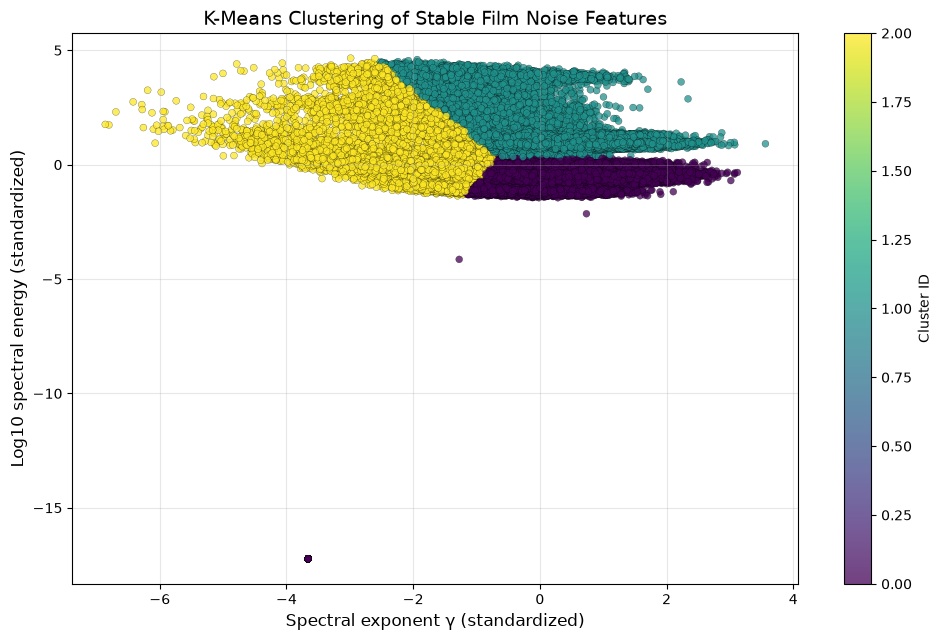

In [9]:
def plot_clusters(X_scaled, labels, path):
    plt.figure(figsize=(10, 6.5))

    scatter = plt.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=25,
        alpha=0.75,
        edgecolor="black",
        linewidth=0.2,
    )

    plt.xlabel("Spectral exponent γ (standardized)", fontsize=12)
    plt.ylabel("Log10 spectral energy (standardized)", fontsize=12)
    plt.title("K-Means Clustering of Stable Film Noise Features", fontsize=14)
    plt.colorbar(scatter, label="Cluster ID")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


plot_clusters(
    X_train_scaled,
    cluster_labels,
    FIGURES_DIR / "kmeans_clusters.png",
)

## K-Nearest Neighbors

KNN is trained on standardized spectral features and evaluated on the held-out
test set.

In [10]:
knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, knn_pred)

print(f"KNN accuracy: {knn_accuracy * 100:.2f}%")
print(
    classification_report(
        y_test,
        knn_pred,
        labels=MATERIAL_ORDER,
        target_names=[MATERIAL_NAMES[label] for label in MATERIAL_ORDER],
        zero_division=0,
    )
)

KNN accuracy: 86.10%


               precision    recall  f1-score   support

 Bismuth (Bi)       0.80      0.78      0.79     31684
Chromium (Cr)       0.79      0.82      0.81     31685
    Iron (Fe)       0.98      0.99      0.99     31685

     accuracy                           0.86     95054
    macro avg       0.86      0.86      0.86     95054
 weighted avg       0.86      0.86      0.86     95054



## Neural network classifier

A multilayer perceptron is trained on the same standardized features.

In [11]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    max_iter=1000,
    early_stopping=True,
    random_state=RANDOM_STATE,
)

mlp.fit(X_train_scaled, y_train)

mlp_pred = mlp.predict(X_test_scaled)
mlp_accuracy = accuracy_score(y_test, mlp_pred)

print(f"Neural network accuracy: {mlp_accuracy * 100:.2f}%")
print(
    classification_report(
        y_test,
        mlp_pred,
        labels=MATERIAL_ORDER,
        target_names=[MATERIAL_NAMES[label] for label in MATERIAL_ORDER],
        zero_division=0,
    )
)

Neural network accuracy: 88.23%


               precision    recall  f1-score   support

 Bismuth (Bi)       0.83      0.81      0.82     31684
Chromium (Cr)       0.83      0.84      0.83     31685
    Iron (Fe)       0.98      0.99      0.99     31685

     accuracy                           0.88     95054
    macro avg       0.88      0.88      0.88     95054
 weighted avg       0.88      0.88      0.88     95054



## Neural network confusion matrix

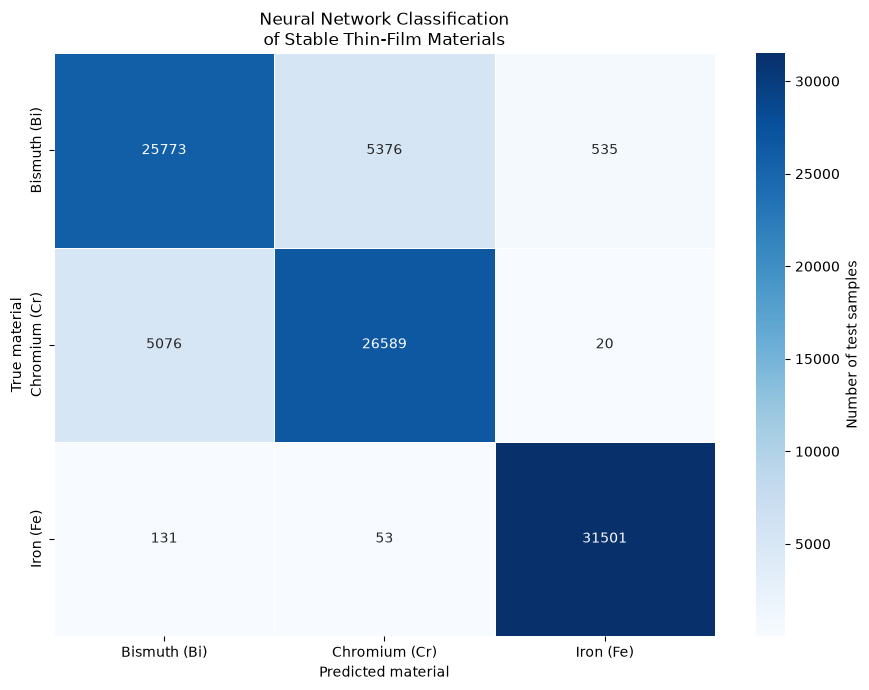

In [12]:
def plot_confusion_matrix(y_test, y_pred, labels, path):
    readable_labels = [MATERIAL_NAMES[label] for label in labels]
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    plt.figure(figsize=(9, 7))

    ax = sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=readable_labels,
        yticklabels=readable_labels,
        cbar_kws={"label": "Number of test samples"},
        linewidths=0.5,
        linecolor="white",
    )

    ax.set_xlabel("Predicted material")
    ax.set_ylabel("True material")
    ax.set_title("Neural Network Classification\nof Stable Thin-Film Materials")

    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    y_test=y_test,
    y_pred=mlp_pred,
    labels=MATERIAL_ORDER,
    path=FIGURES_DIR / "neural_network_confusion_matrix.png",
)

## Apply the trained model to irradiated films

Irradiated films were not used for training. The trained neural network is
applied to them to obtain predicted material labels and confidence values.

In [13]:
df_irradiated = df[df["irradiated"] == True].copy()

if df_irradiated.empty:
    print("No irradiated films found.")
else:
    X_irradiated = df_irradiated[["gamma", "log_energy"]].copy()
    X_irradiated_scaled = scaler.transform(X_irradiated)

    df_irradiated["predicted_material"] = mlp.predict(X_irradiated_scaled)

    if hasattr(mlp, "predict_proba"):
        probabilities = mlp.predict_proba(X_irradiated_scaled)
        df_irradiated["prediction_confidence"] = probabilities.max(axis=1)

    df_irradiated[
        [
            "file",
            "material",
            "gamma",
            "log_energy",
            "predicted_material",
            "prediction_confidence",
        ]
    ].head()

## File-level comparison of spectral features

The plots compare stable and irradiated films at the file level.

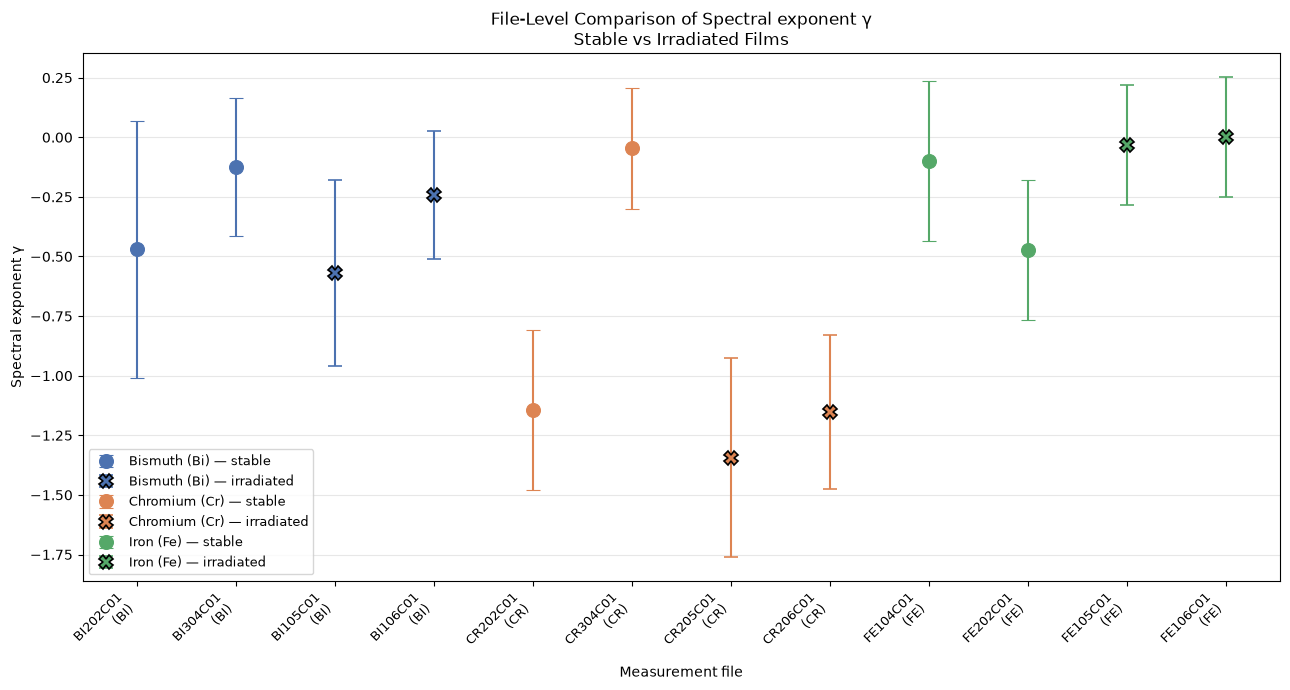

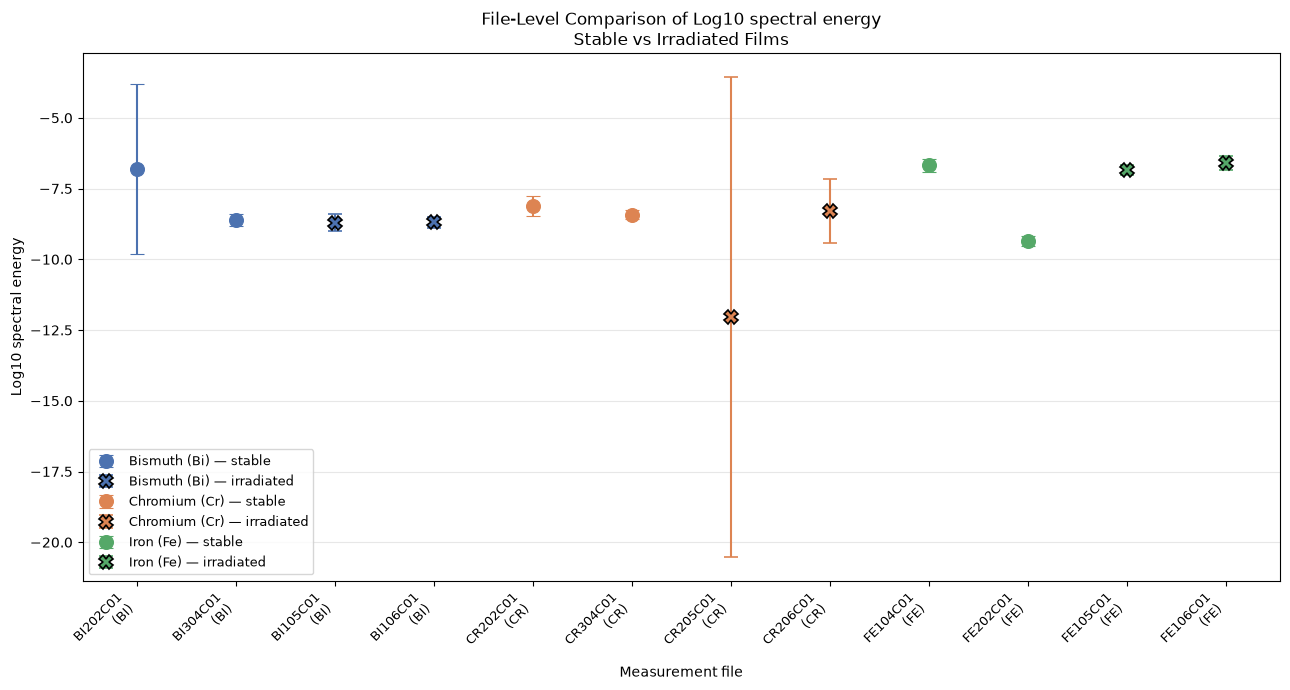

In [14]:
def plot_file_level_comparison(df, feature, ylabel, filename):
    summary = (
        df[df["material"] != REFERENCE_LABEL]
        .groupby(["file", "material", "irradiated"], as_index=False)
        .agg(
            mean_value=(feature, "mean"),
            std_value=(feature, "std"),
            n_samples=(feature, "size"),
        )
    )

    summary["label"] = summary["file"] + "\n(" + summary["material"] + ")"

    summary = summary.sort_values(
        ["material", "irradiated", "file"],
        ascending=[True, True, True],
    )

    plt.figure(figsize=(13, 7))

    for material in MATERIAL_ORDER:
        material_summary = summary[summary["material"] == material]

        for _, row in material_summary.iterrows():
            marker = "o" if not row["irradiated"] else "X"
            edgecolor = (
                "black" if row["irradiated"] else MATERIAL_COLORS[material]
            )
            linewidth = 1.2 if row["irradiated"] else 0.8

            plt.errorbar(
                row["label"],
                row["mean_value"],
                yerr=row["std_value"],
                fmt=marker,
                markersize=10,
                color=MATERIAL_COLORS[material],
                markeredgecolor=edgecolor,
                markeredgewidth=linewidth,
                capsize=5,
                elinewidth=1.5,
                label=(
                    f"{MATERIAL_NAMES[material]} — "
                    + ("irradiated" if row["irradiated"] else "stable")
                ),
            )

    plt.ylabel(ylabel)
    plt.xlabel("Measurement file")
    plt.title(
        f"File-Level Comparison of {ylabel}\nStable vs Irradiated Films"
    )
    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.grid(True, axis="y", alpha=0.3)

    handles, labels = plt.gca().get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    plt.legend(unique.values(), unique.keys(), fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


plot_file_level_comparison(
    df=df,
    feature="gamma",
    ylabel="Spectral exponent γ",
    filename="file_level_gamma_comparison.png",
)

plot_file_level_comparison(
    df=df,
    feature="log_energy",
    ylabel="Log10 spectral energy",
    filename="file_level_energy_comparison.png",
)

## Feature distributions by file

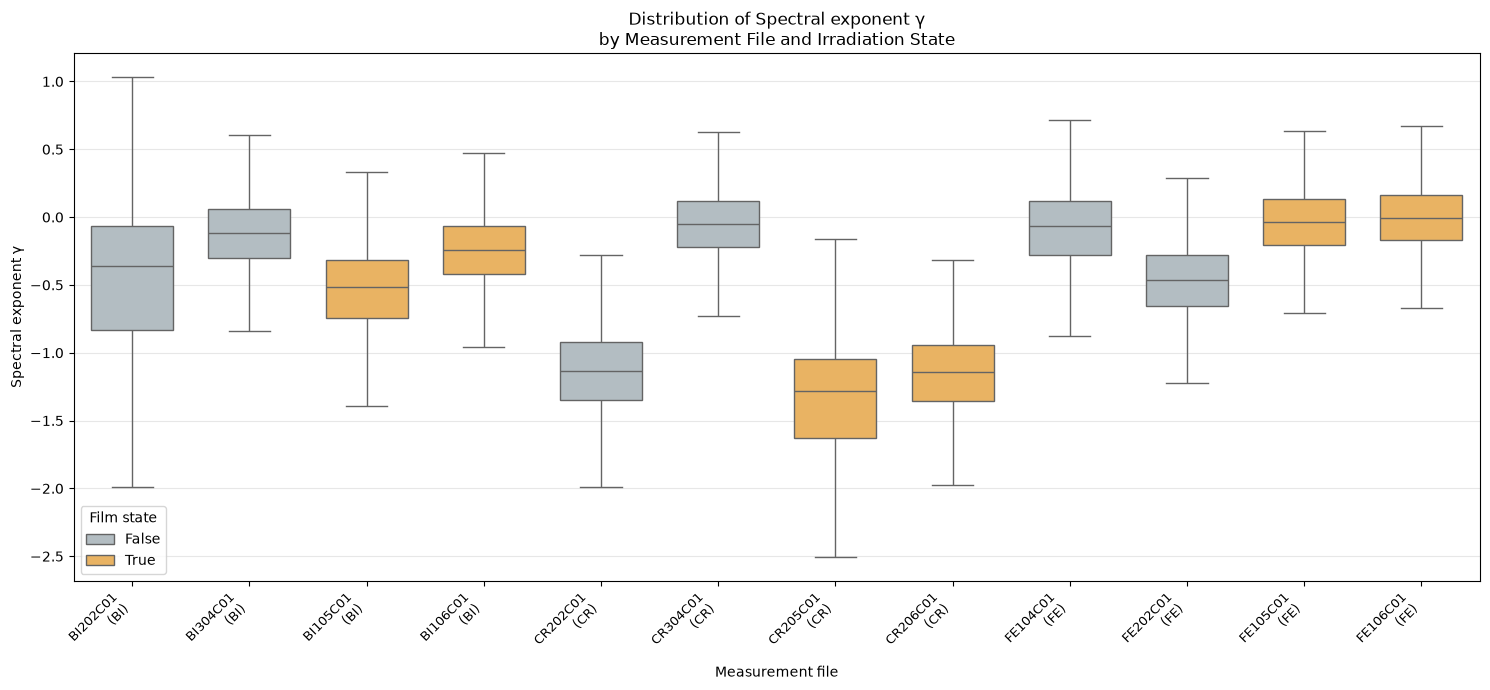

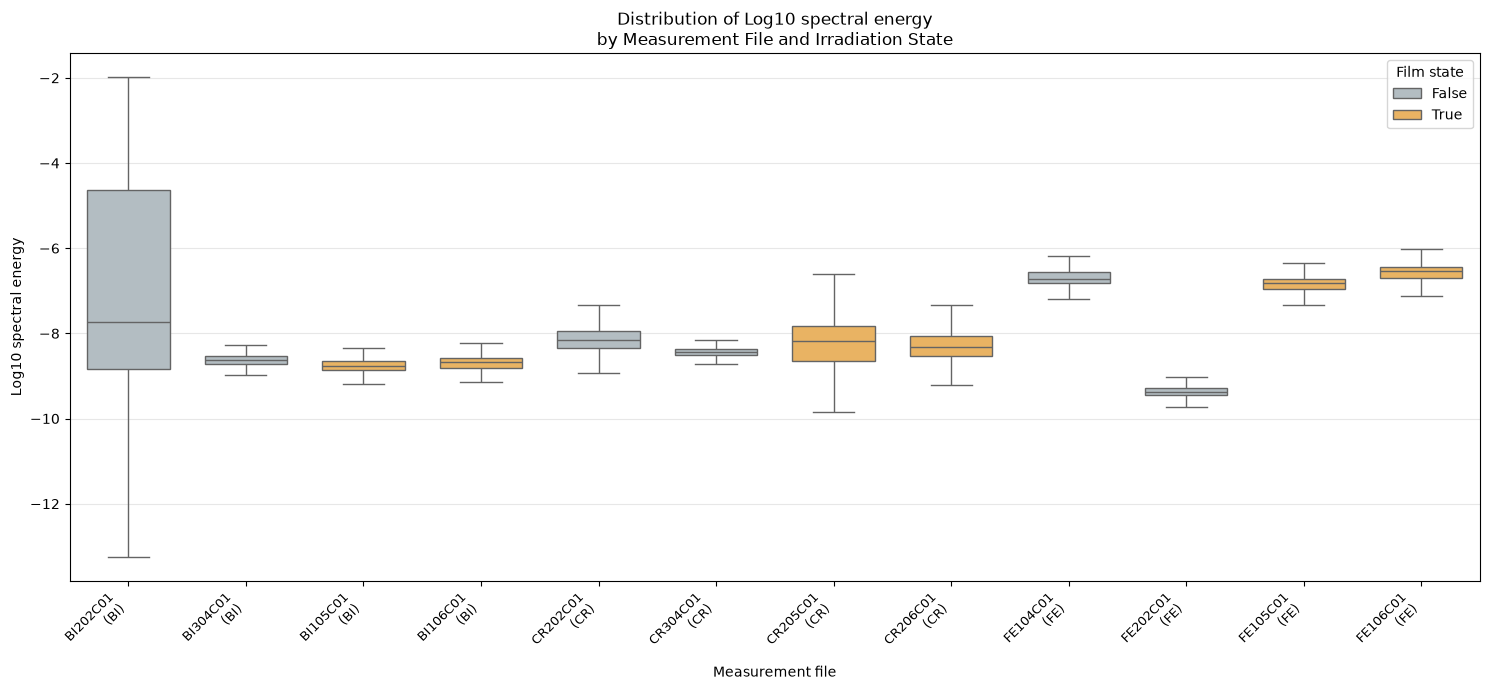

In [15]:
def plot_feature_boxplots(df, feature, ylabel, filename):
    plot_df = df[df["material"] != REFERENCE_LABEL].copy()
    plot_df["file_label"] = (
        plot_df["file"] + "\n(" + plot_df["material"] + ")"
    )

    file_order = (
        plot_df[["file", "material", "irradiated"]]
        .drop_duplicates()
        .sort_values(["material", "irradiated", "file"])
    )

    ordered_labels = [
        f"{row['file']}\n({row['material']})"
        for _, row in file_order.iterrows()
    ]

    plt.figure(figsize=(15, 7))

    sns.boxplot(
        data=plot_df,
        x="file_label",
        y=feature,
        hue="irradiated",
        order=ordered_labels,
        palette={False: "#B0BEC5", True: "#FFB74D"},
        showfliers=False,
        width=0.7,
    )

    plt.ylabel(ylabel)
    plt.xlabel("Measurement file")
    plt.title(
        f"Distribution of {ylabel}\n"
        "by Measurement File and Irradiation State"
    )
    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.grid(True, axis="y", alpha=0.3)
    plt.legend(title="Film state")

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


plot_feature_boxplots(
    df=df,
    feature="gamma",
    ylabel="Spectral exponent γ",
    filename="gamma_boxplots_by_file.png",
)

plot_feature_boxplots(
    df=df,
    feature="log_energy",
    ylabel="Log10 spectral energy",
    filename="energy_boxplots_by_file.png",
)

## Save metrics and irradiated-film predictions

In [16]:
metrics = pd.DataFrame(
    [
        {
            "model": "K-Means",
            "metric": "silhouette_score",
            "value": silhouette,
        },
        {
            "model": "KNN",
            "metric": "accuracy",
            "value": knn_accuracy,
        },
        {
            "model": "Neural network",
            "metric": "accuracy",
            "value": mlp_accuracy,
        },
    ]
)

metrics_path = METRICS_DIR / "model_metrics.csv"
metrics.to_csv(metrics_path, index=False)

print(metrics)
print(f"Metrics saved: {metrics_path}")

            model            metric     value
0         K-Means  silhouette_score  0.509831
1             KNN          accuracy  0.860995
2  Neural network          accuracy  0.882267
Metrics saved: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\results\metrics\model_metrics.csv


In [17]:
if not df_irradiated.empty:
    predictions_path = METRICS_DIR / "irradiated_film_predictions.csv"
    df_irradiated.to_csv(predictions_path, index=False)
    print(f"Irradiated film predictions saved: {predictions_path}")
else:
    print("No irradiated film predictions were saved.")

Irradiated film predictions saved: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\results\metrics\irradiated_film_predictions.csv


## Result files

The notebook creates the same main outputs as `src/train_models.py`:

- `results/figures/kmeans_clusters.png`
- `results/figures/neural_network_confusion_matrix.png`
- `results/figures/file_level_gamma_comparison.png`
- `results/figures/file_level_energy_comparison.png`
- `results/figures/gamma_boxplots_by_file.png`
- `results/figures/energy_boxplots_by_file.png`
- `results/metrics/model_metrics.csv`
- `results/metrics/irradiated_film_predictions.csv`